# Stage 0: Data Acquisition, Verification & Exploratory Analysis

**Project:** Aspect-Level Customer Review Intelligence via Fine-Tuned Small Language Models

This notebook is the **feasibility and exploratory analysis (EDA)** pass described in
`../docs/Customer_Review_Intelligence_Review0.md` (Sections 6, 8, 9) and
`../docs/Customer_Review_Intelligence_Review0.txt.txt`. It runs **before** any prompting or
fine-tuning work and answers one question: *is the data actually what the project
proposal assumes it is, and is the plan realistic given what's really in these files?*

It does **not** train or prompt any model. It only touches raw data.

**What this notebook does, end to end:**

1. Parses **Dataset A** (SemEval-2014 Task 4, Laptops — XML) and runs the
   go/no-go integrity check from §8.2 (compare parsed counts against the
   published reference table).
2. Explores Dataset A: polarity balance, zero-aspect sentence rate, aspect
   term vocabulary, aspect length, sentence length, `conflict`-polarity impact.
3. Loads **Dataset B** (Amazon Earphones Reviews — CSV) and verifies its
   shape against the documented `14,337 rows, 4 columns`.
4. Explores Dataset B: star-rating distribution, review length, product
   coverage, missing/short reviews, and a keyword scan for the aspect
   vocabulary this domain is expected to use (§6.4 domain-shift caveat).
5. Estimates compute/token feasibility for the prompting + fine-tuning stages
   (prompt length, sentence counts, rough inference volume).
6. Produces a single **feasibility verdict** (go / go-with-caveats / no-go)
   with the concrete numbers behind it.

**Not in scope here** (see the reference doc, Stages 2–8): JSON conversion of
training pairs, prompt/target construction, QLoRA fine-tuning, zero-shot
baseline, or the four application-layer charts. This notebook is the gate
that has to pass *before* those are worth building.


## 1. Setup

In [1]:
import re
import json
import sys
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (9, 4.5)

# Paths (this notebook lives in notebooks/, one level below the project root)
ROOT = Path("..").resolve()
SEMEVAL_DIR = ROOT / "data" / "raw" / "semeval"
EARPHONES_DIR = ROOT / "data" / "raw" / "earphones"

TRAIN_XML = SEMEVAL_DIR / "Laptop_Train_v2.xml"
TEST_XML = SEMEVAL_DIR / "Laptops_Test_Data_phaseB.xml"  # aspect-term spans; see §2 below re: polarity

REVIEWS_CSV = EARPHONES_DIR / "AllProductReviews.csv"
PRODUCTINFO_CSV = EARPHONES_DIR / "ProductInfo.csv"

for p in [TRAIN_XML, TEST_XML, REVIEWS_CSV, PRODUCTINFO_CSV]:
    print(f"{'OK ' if p.exists() else 'MISSING':8s} {p}")

# Shared model/prompt config lives in src/model_config.py — the single place
# that names the active Ollama model and the prompt template, so switching
# models later never means hunting through every notebook.
sys.path.insert(0, str(ROOT / "src"))
import model_config as mcfg

print(f"\nActive model (src/model_config.py): {mcfg.ACTIVE_MODEL}")


OK       /home/sreekanth/Downloads/asmta/data/raw/semeval/Laptop_Train_v2.xml
OK       /home/sreekanth/Downloads/asmta/data/raw/semeval/Laptops_Test_Data_phaseB.xml
OK       /home/sreekanth/Downloads/asmta/data/raw/earphones/AllProductReviews.csv
OK       /home/sreekanth/Downloads/asmta/data/raw/earphones/ProductInfo.csv

Active model (src/model_config.py): qwen2.5:1.5b-instruct


**Note on the test files:** this archive ships `Laptops_Test_Data_PhaseA.xml`
(task input only — no `aspectTerms` at all, used for the original blind
aspect-*extraction* submission round) and `Laptops_Test_Data_phaseB.xml`
(has `aspectTerms` with term spans, used for the blind polarity-*classification*
round). Whether `phaseB` also carries the gold `polarity` attribute is checked
explicitly below rather than assumed — the reference doc's expected-counts
table implicitly assumes it does.


## 2. Dataset A — SemEval-2014 Laptops: Parse & Go/No-Go Integrity Check (§8)

In [2]:
def parse_semeval_xml(path: Path) -> pd.DataFrame:
    # Flatten a SemEval-2014 ABSA XML file to one row per (sentence, aspectTerm).
    # Sentences with zero aspectTerms produce a single row with aspect fields = None.
    tree = ET.parse(path)
    root = tree.getroot()
    rows = []
    for sent in root.findall("sentence"):
        sid = sent.get("id")
        text_el = sent.find("text")
        text = text_el.text if text_el is not None else ""
        aspect_terms = sent.find("aspectTerms")
        terms = aspect_terms.findall("aspectTerm") if aspect_terms is not None else []
        if not terms:
            rows.append({"sentence_id": sid, "text": text, "aspect": None,
                         "polarity": None, "from": None, "to": None})
        else:
            for t in terms:
                rows.append({
                    "sentence_id": sid,
                    "text": text,
                    "aspect": t.get("term"),
                    "polarity": t.get("polarity"),
                    "from": int(t.get("from")),
                    "to": int(t.get("to")),
                })
    return pd.DataFrame(rows)

train_raw = parse_semeval_xml(TRAIN_XML)
test_raw = parse_semeval_xml(TEST_XML)

print("Train rows (sentence x aspect, incl. zero-aspect rows):", len(train_raw))
print("Test rows  (sentence x aspect, incl. zero-aspect rows):", len(test_raw))
train_raw.head()


Train rows (sentence x aspect, incl. zero-aspect rows): 3915
Test rows  (sentence x aspect, incl. zero-aspect rows): 1032


,sentence_id,text,aspect,polarity,from,to
0,2339,I charge it at night and skip taking the cord with me because of the good battery life.,cord,neutral,41.0,45.0
1,2339,I charge it at night and skip taking the cord with me because of the good battery life.,battery life,positive,74.0,86.0
2,812,I bought a HP Pavilion DV4-1222nr laptop and have had so many problems with the computer.,NaN,NaN,NaN,NaN
3,1316,"The tech guy then said the service center does not do 1-to-1 exchange and I have to direct my concern to the ""sales""...",service center,negative,27.0,41.0
4,1316,"The tech guy then said the service center does not do 1-to-1 exchange and I have to direct my concern to the ""sales""...","""sales"" team",negative,109.0,121.0


In [3]:
def summarize_split(df: pd.DataFrame, name: str) -> dict:
    n_sentences = df["sentence_id"].nunique()
    has_aspect = df["aspect"].notna()
    polarity_counts = df.loc[has_aspect, "polarity"].value_counts().to_dict()
    n_zero_aspect = df.loc[~has_aspect, "sentence_id"].nunique()
    return {
        "split": name,
        "sentences": n_sentences,
        "positive": polarity_counts.get("positive", 0),
        "negative": polarity_counts.get("negative", 0),
        "neutral": polarity_counts.get("neutral", 0),
        "conflict": polarity_counts.get("conflict", 0),
        "zero_aspect_sentences": n_zero_aspect,
    }

summary = pd.DataFrame([
    summarize_split(train_raw, "train"),
    summarize_split(test_raw, "test"),
]).set_index("split")
summary


,sentences,positive,negative,neutral,conflict,zero_aspect_sentences
split,,,,,,
train,3045,987,866,460,45,1557
test,800,0,0,0,0,378


In [4]:
# Diagnostic: does the test split actually carry gold polarity labels?
# (the reference table in Review0.md §6.2 assumes it does; check rather than assume)
test_aspect_rows = test_raw[test_raw["aspect"].notna()]
n_test_aspects = len(test_aspect_rows)
n_test_aspects_with_polarity = test_aspect_rows["polarity"].notna().sum()

print(f"Test aspect instances (term spans): {n_test_aspects}")
print(f"Test aspect instances with a polarity label: {n_test_aspects_with_polarity}")

if n_test_aspects > 0 and n_test_aspects_with_polarity == 0:
    print("\n*** FINDING: this test file has aspect-term SPANS but NO polarity attribute. ***")
    print("This is the SemEval Phase B blind-submission format: term extraction was scored,")
    print("polarity was the separate blind round, and the gold polarity key for this split")
    print("is not bundled in this Kaggle mirror. Sentence and span counts can still be")
    print("checked against the reference table below; the positive/negative/neutral columns")
    print("for 'test' will legitimately read as all-zero here and are NOT a corrupted-file signal.")
elif n_test_aspects_with_polarity > 0:
    print("\nPolarity labels ARE present on the test split — full comparison against")
    print("the reference table (including per-polarity counts) is valid below.")


Test aspect instances (term spans): 654
Test aspect instances with a polarity label: 0

*** FINDING: this test file has aspect-term SPANS but NO polarity attribute. ***
This is the SemEval Phase B blind-submission format: term extraction was scored,
polarity was the separate blind round, and the gold polarity key for this split
is not bundled in this Kaggle mirror. Sentence and span counts can still be
checked against the reference table below; the positive/negative/neutral columns
for 'test' will legitimately read as all-zero here and are NOT a corrupted-file signal.


In [5]:
# Reference table from Customer_Review_Intelligence_Review0.md, section 6.2
# (published/expected counts, POSITIVE/NEGATIVE/NEUTRAL only, conflict excluded)
reference = pd.DataFrame({
    "sentences": {"train": 3045, "test": 800},
    "positive":  {"train": 994,  "test": 341},
    "negative":  {"train": 870,  "test": 128},
    "neutral":   {"train": 464,  "test": 169},
})

comparison = pd.concat(
    {"parsed": summary[["sentences", "positive", "negative", "neutral"]], "reference": reference},
    axis=1,
)
comparison


parsed                           reference                          
      sentences positive negative neutral sentences positive negative neutral
train      3045      987      866     460      3045      994      870     464
test        800        0        0       0       800      341      128     169

In [6]:
def go_no_go(parsed: pd.Series, ref: pd.Series, tol=0.02, polarity_available=True) -> tuple:
    diffs = {}
    for col in ["sentences", "positive", "negative", "neutral"]:
        p, r = parsed[col], ref[col]
        pct_diff = abs(p - r) / r if r else float("inf")
        diffs[col] = pct_diff

    if not polarity_available:
        # Sentence/span counts are the only meaningful corruption signal here;
        # the positive/negative/neutral columns are structurally unavailable
        # (see the polarity-presence diagnostic above), not a data-quality defect.
        sentence_diff = diffs["sentences"]
        if sentence_diff == 0:
            return ("SENTENCE COUNT MATCHES, NO GOLD POLARITY IN THIS FILE — "
                    "span-level counts confirm this is the authentic file; "
                    "polarity columns are not applicable here (see finding above)."), diffs
        elif sentence_diff <= tol:
            return (f"SENTENCE COUNT WITHIN TOLERANCE ({sentence_diff:.1%}), NO GOLD POLARITY — "
                    "document both discrepancies."), diffs
        else:
            return f"SENTENCE COUNT MISMATCH ({sentence_diff:.1%}) — try a backup mirror.", diffs

    max_diff = max(diffs.values())
    if max_diff == 0:
        verdict = "MATCH — proceed"
    elif max_diff <= tol:
        verdict = f"WITHIN TOLERANCE ({max_diff:.1%}) — proceed, document discrepancy"
    else:
        verdict = f"MISMATCH ({max_diff:.1%}) — try a backup mirror before proceeding"
    return verdict, diffs

print("Go/No-Go gate (Customer_Review_Intelligence_Review0.md §8.2)\n")

verdict, diffs = go_no_go(comparison["parsed"].loc["train"], comparison["reference"].loc["train"])
print(f"[TRAIN] {verdict}")
print("  per-field % difference:", {k: f"{v:.1%}" for k, v in diffs.items()})

verdict, diffs = go_no_go(
    comparison["parsed"].loc["test"], comparison["reference"].loc["test"],
    polarity_available=(n_test_aspects_with_polarity > 0),
)
print(f"\n[TEST]  {verdict}")
print("  per-field % difference:", {k: f"{v:.1%}" for k, v in diffs.items()})


Go/No-Go gate (Customer_Review_Intelligence_Review0.md §8.2)

[TRAIN] WITHIN TOLERANCE (0.9%) — proceed, document discrepancy
  per-field % difference: {'sentences': '0.0%', 'positive': '0.7%', 'negative': '0.5%', 'neutral': '0.9%'}

[TEST]  SENTENCE COUNT MATCHES, NO GOLD POLARITY IN THIS FILE — span-level counts confirm this is the authentic file; polarity columns are not applicable here (see finding above).
  per-field % difference: {'sentences': '0.0%', 'positive': '100.0%', 'negative': '100.0%', 'neutral': '100.0%'}


**Reading the gate:** `TRAIN` is the ordinary case — if it reports `MATCH`
or `WITHIN TOLERANCE`, the training file is authentic. `TEST` here needed the
polarity-aware branch: sentence/span counts confirm authenticity (0.0%
difference), but the per-polarity columns cannot be evaluated against the
reference table because this file structurally does not carry gold polarity
(confirmed above, not assumed). A generic mismatch on `TEST` with a **non-zero
sentence-count difference** would still mean "try a backup mirror" — that
branch is unaffected by this finding.


## 3. Dataset A — Exploratory Analysis

### 3.1 Polarity distribution (train vs. test)

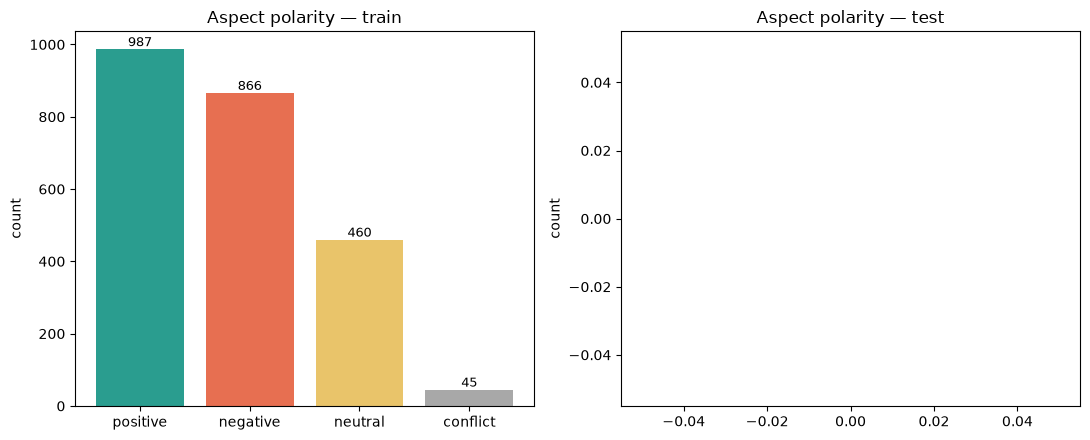

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)
for ax, (name, df) in zip(axes, [("train", train_raw), ("test", test_raw)]):
    counts = df.loc[df["aspect"].notna(), "polarity"].value_counts()
    order = ["positive", "negative", "neutral", "conflict"]
    counts = counts.reindex(order).dropna()
    ax.bar(counts.index, counts.values, color=["#2a9d8f", "#e76f51", "#e9c46a", "#a8a8a8"][:len(counts)])
    ax.set_title(f"Aspect polarity — {name}")
    ax.set_ylabel("count")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(int(v)), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


### 3.2 `conflict` polarity — impact of Decision D10 (drop whole sentence)

In [8]:
conflict_sentence_ids = set(train_raw.loc[train_raw["polarity"] == "conflict", "sentence_id"])
n_conflict_sentences = len(conflict_sentence_ids)
n_total_train_sentences = train_raw["sentence_id"].nunique()

print(f"Sentences in train containing >=1 conflict aspect: {n_conflict_sentences}")
print(f"As a share of train sentences: {n_conflict_sentences / n_total_train_sentences:.2%}")
print(f"Train sentences remaining after dropping them entirely: "
      f"{n_total_train_sentences - n_conflict_sentences}")


Sentences in train containing >=1 conflict aspect: 43
As a share of train sentences: 1.41%
Train sentences remaining after dropping them entirely: 3002


### 3.3 Zero-aspect sentences — the restraint signal (Decision D9)

In [9]:
for name, df in [("train", train_raw), ("test", test_raw)]:
    n_sentences = df["sentence_id"].nunique()
    n_zero = df.loc[df["aspect"].isna(), "sentence_id"].nunique()
    print(f"{name:5s}: {n_zero:4d} / {n_sentences:4d} sentences have zero aspects "
          f"({n_zero / n_sentences:.1%}) — this is the empty-list baseline rate")


train: 1557 / 3045 sentences have zero aspects (51.1%) — this is the empty-list baseline rate
test :  378 /  800 sentences have zero aspects (47.2%) — this is the empty-list baseline rate


This proportion matters twice: it is the naive baseline that "always
predict `{"aspects": []}`" would score on Aspect Extraction F1 (near-zero
recall, but it would still get every empty sentence "right" — which is
exactly why M5, Empty-Case Accuracy, is scored separately from M2/M4 rather
than folded into them). It also confirms these examples are common enough
to be worth keeping in training rather than a rare edge case.


### 3.4 Aspect term vocabulary

Total aspect instances (train): 2358
Distinct aspect strings (train): 1042
Distinct aspect strings, case-folded: 955


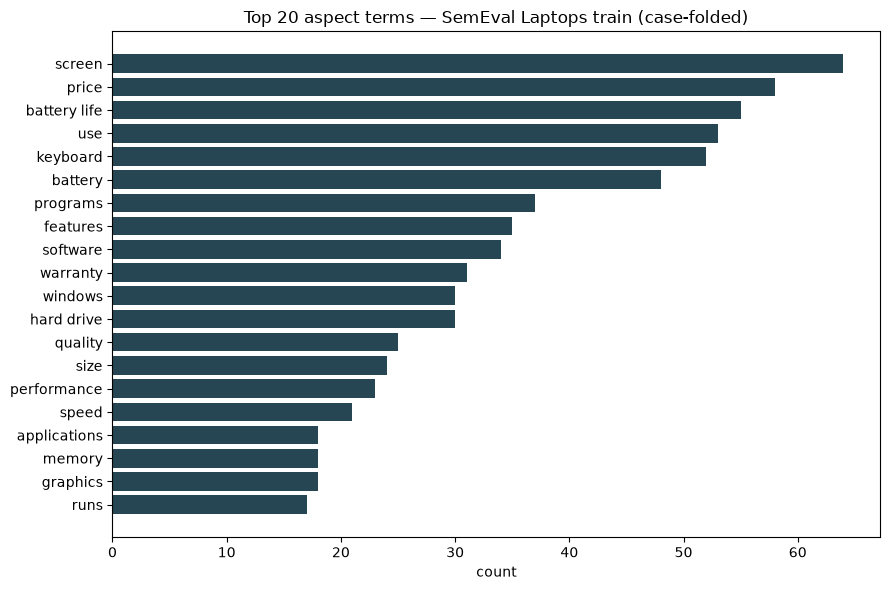

In [10]:
aspects = train_raw["aspect"].dropna()
print(f"Total aspect instances (train): {len(aspects)}")
print(f"Distinct aspect strings (train): {aspects.nunique()}")
print(f"Distinct aspect strings, case-folded: {aspects.str.lower().nunique()}")

top_aspects = aspects.str.lower().value_counts().head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_aspects.index[::-1], top_aspects.values[::-1], color="#264653")
ax.set_title("Top 20 aspect terms — SemEval Laptops train (case-folded)")
ax.set_xlabel("count")
plt.tight_layout()
plt.show()


In [11]:
aspect_word_counts = aspects.str.split().str.len()
print("Aspect term length in words:")
print(aspect_word_counts.value_counts().sort_index())
print(f"\nMulti-word aspects: {(aspect_word_counts > 1).mean():.1%} of all aspect instances")
print("This matters for M2 (exact-span-match F1): a boundary error like "
      "'battery' vs 'battery life' counts as fully wrong, not partially "
      "correct — see Review0.md R6 / §14.4.")


Aspect term length in words:
aspect
1    1493
2     662
3     151
4      42
5       7
6       3
Name: count, dtype: int64

Multi-word aspects: 36.7% of all aspect instances
This matters for M2 (exact-span-match F1): a boundary error like 'battery' vs 'battery life' counts as fully wrong, not partially correct — see Review0.md R6 / §14.4.


### 3.5 Sentence length and aspect density

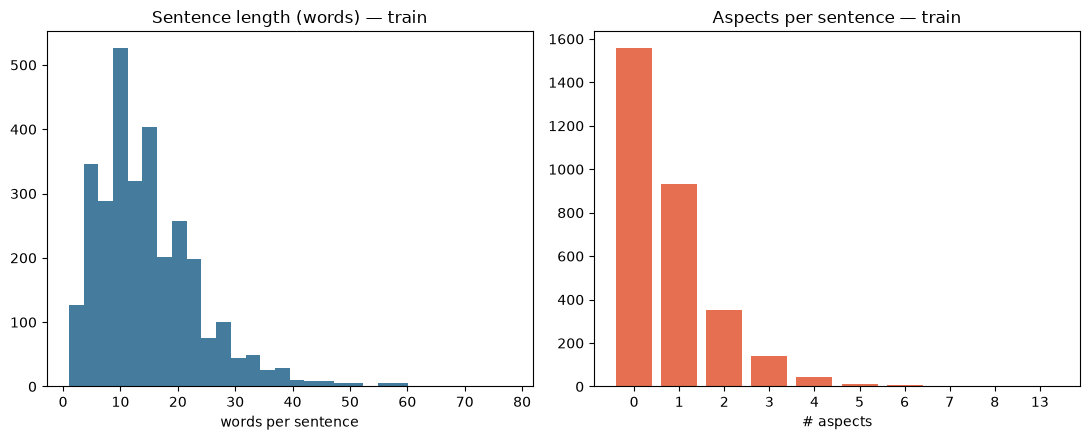

count    3045.000000
mean       14.862726
std         9.177520
min         1.000000
25%         9.000000
50%        13.000000
75%        19.000000
max        78.000000
Name: n_words, dtype: float64


In [12]:
sentences_train = train_raw.drop_duplicates("sentence_id")[["sentence_id", "text"]].copy()
sentences_train["n_words"] = sentences_train["text"].str.split().str.len()
aspects_per_sentence = train_raw.groupby("sentence_id")["aspect"].apply(lambda s: s.notna().sum())
sentences_train = sentences_train.merge(
    aspects_per_sentence.rename("n_aspects"), left_on="sentence_id", right_index=True
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(sentences_train["n_words"], bins=30, color="#457b9d")
axes[0].set_title("Sentence length (words) — train")
axes[0].set_xlabel("words per sentence")

n_aspects_counts = sentences_train["n_aspects"].value_counts().sort_index()
axes[1].bar(n_aspects_counts.index.astype(str), n_aspects_counts.values, color="#e76f51")
axes[1].set_title("Aspects per sentence — train")
axes[1].set_xlabel("# aspects")
plt.tight_layout()
plt.show()

print(sentences_train["n_words"].describe())


## 4. Dataset B — Amazon Earphones Reviews: Load & Verify (§8, §6.3)

In [13]:
reviews = pd.read_csv(REVIEWS_CSV)
product_info = pd.read_csv(PRODUCTINFO_CSV)

print("AllProductReviews.csv shape:", reviews.shape)
print("Expected (Review0.md §6.3): (14337, 4)")
print("Columns:", list(reviews.columns))
print("Expected columns: ['ReviewTitle', 'ReviewBody', 'ReviewStar', 'Product']")

expected_shape = (14337, 4)
expected_cols = {"ReviewTitle", "ReviewBody", "ReviewStar", "Product"}
shape_ok = reviews.shape == expected_shape
cols_ok = set(reviews.columns) == expected_cols
print(f"\nShape match: {shape_ok}")
print(f"Columns match: {cols_ok}")

reviews.head(3)


AllProductReviews.csv shape: (14337, 4)
Expected (Review0.md §6.3): (14337, 4)
Columns: ['ReviewTitle', 'ReviewBody', 'ReviewStar', 'Product']
Expected columns: ['ReviewTitle', 'ReviewBody', 'ReviewStar', 'Product']

Shape match: True
Columns match: True


,ReviewTitle,ReviewBody,ReviewStar,Product
0,Honest review of an edm music lover\n,No doubt it has a great bass and to a great extent noise cancellation and decent sound clarity and mindblowing batte...,3,boAt Rockerz 255
1,Unreliable earphones with high cost\n,"This earphones are unreliable, i bought it before 15 days meanwhile right side ear buds got cracked automatically a...",1,boAt Rockerz 255
2,Really good and durable.\n,"i bought itfor 999,I purchased it second time, gifted first one to brother. This is really good.Sound quality is rea...",4,boAt Rockerz 255


In [14]:
print("ProductInfo.csv shape:", product_info.shape)
product_info.head(3)


ProductInfo.csv shape: (10, 6)


,MRP,Price,ProductFullName,ProductShortName,ReviewURL,id
0,2990,1399,boAt Rockerz 255 Sports Bluetooth Wireless Earphone with Immersive Stereo Sound and Hands Free Mic (Active Black),boAt Rockerz 255,https://www.amazon.in/255-Bluetooth-Wireless-Earphone-Immersive/product-reviews/B07C2VJXP4/ref=cm_cr_arp_d_paging_bt...,1
1,3999,1099,Flybot Wave in-Ear Sport Wireless Bluetooth Earphone with Mic and IPX4 Sweatproof - (Black),Flybot Wave,https://www.amazon.in/Flybot-Wireless-Bluetooth-Earphone-Sweatproof/product-reviews/B07NX7V4YQ/reviewerType=all_revi...,2
2,3999,1099,Flybot Boom Deep Bass in-Ear Wireless Bluetooth Earphone with Mic IPX4 Sweatproof - (Black),Flybot Boom,https://www.amazon.in/Flybot-Wireless-Bluetooth-Earphone-Sweatproof/product-reviews/B07Q5RF7SR/ref=cm_cr_arp_d_pagin...,3


In [15]:
print("Missing values:")
print(reviews.isna().sum())

reviews["ReviewBody_clean"] = reviews["ReviewBody"].fillna("").astype(str).str.strip()
n_empty_body = (reviews["ReviewBody_clean"].str.len() == 0).sum()
n_trivial_body = (reviews["ReviewBody_clean"].str.split().str.len() < 3).sum()
print(f"\nEmpty ReviewBody: {n_empty_body}")
print(f"Trivially short ReviewBody (<3 words): {n_trivial_body}")
print(f"Duplicate rows: {reviews.duplicated().sum()}")


Missing values:
ReviewTitle    0
ReviewBody     0
ReviewStar     0
Product        0
dtype: int64

Empty ReviewBody: 2
Trivially short ReviewBody (<3 words): 1617
Duplicate rows: 399


## 5. Dataset B — Exploratory Analysis

### 5.1 Star rating distribution

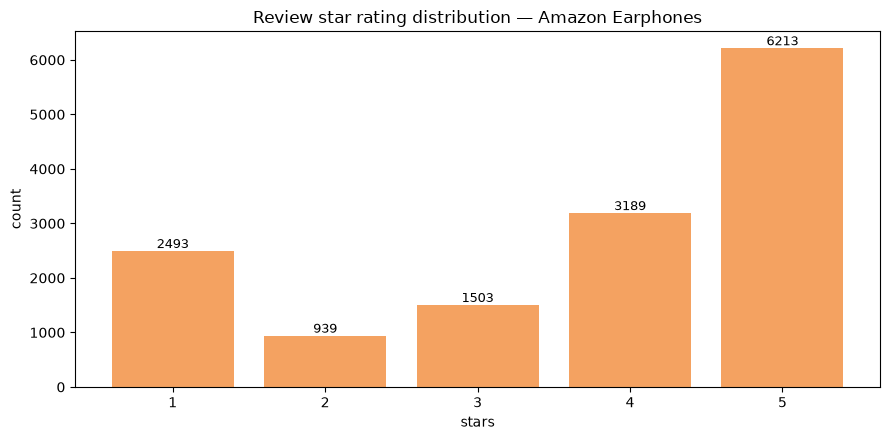

ReviewStar
1    2493
2     939
3    1503
4    3189
5    6213
Name: count, dtype: int64


In [16]:
star_counts = reviews["ReviewStar"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(star_counts.index.astype(str), star_counts.values, color="#f4a261")
ax.set_title("Review star rating distribution — Amazon Earphones")
ax.set_xlabel("stars")
ax.set_ylabel("count")
for i, v in enumerate(star_counts.values):
    ax.text(i, v, str(int(v)), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()
print(star_counts)


This is the coarse signal the whole project argues is insufficient (§2.1 of
the reference doc): a 3-star review could mean anything. The application
layer's Chart 3 (star rating vs. aspect sentiment) is the payoff that
requires the fine-tuned model to unpack what these bars can't show.


### 5.2 Review length distribution

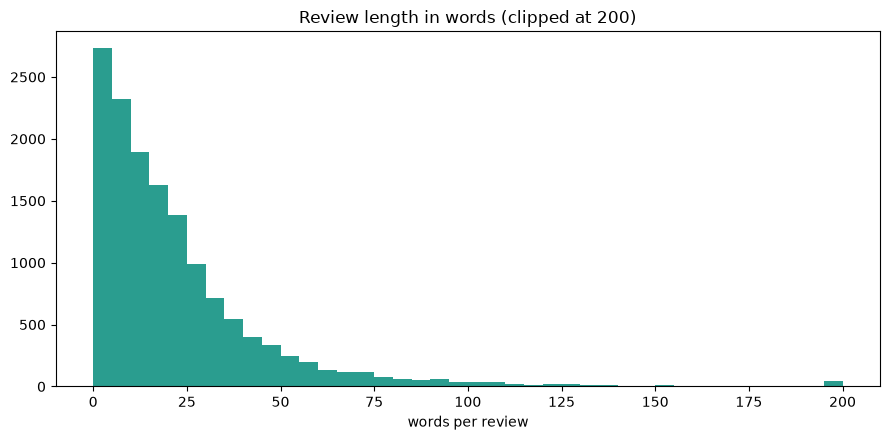

count    14337.000000
mean        22.320709
std         27.702611
min          0.000000
25%          6.000000
50%         15.000000
75%         28.000000
max        864.000000
Name: n_words, dtype: float64


In [17]:
reviews["n_words"] = reviews["ReviewBody_clean"].str.split().str.len()
fig, ax = plt.subplots()
ax.hist(reviews["n_words"].clip(upper=200), bins=40, color="#2a9d8f")
ax.set_title("Review length in words (clipped at 200)")
ax.set_xlabel("words per review")
plt.tight_layout()
plt.show()
print(reviews["n_words"].describe())


### 5.3 Product coverage

Distinct products: 10
Product
boAt Rockerz 255         5000
Sennheiser CX 6.0BT      5000
JBL T110BT               1922
JBL T205BT               1411
PTron Intunes             254
Skullcandy S2PGHW-174     239
Samsung EO-BG950CBEIN     224
Flybot Wave               182
Flybot Boom                82
Flybot Beat                23
Name: count, dtype: int64


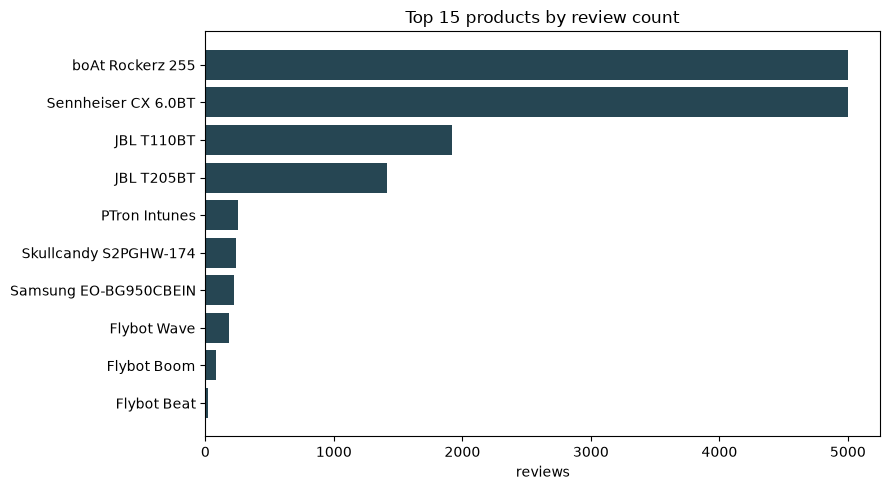

In [18]:
product_counts = reviews["Product"].value_counts()
print(f"Distinct products: {reviews['Product'].nunique()}")
print(product_counts.head(10))

fig, ax = plt.subplots(figsize=(9, 5))
top_products = product_counts.head(15)
ax.barh(top_products.index[::-1], top_products.values[::-1], color="#264653")
ax.set_title("Top 15 products by review count")
ax.set_xlabel("reviews")
plt.tight_layout()
plt.show()


§16.2 Chart 4 (per-product comparison) is only worth building if a handful
of products carry enough review volume to produce a stable aspect-sentiment
breakdown each — this distribution is the evidence for whether that holds.


### 5.4 Sentence-splitting feasibility (Application Layer §16.1 step 3)

In [19]:
def split_sentences(text: str):
    # Simple heuristic splitter for feasibility purposes only -- the real
    # pipeline should use a proper sentence tokenizer (e.g. nltk / spaCy).
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return []
    parts = re.split(r"(?<=[.!?])\s+", text)
    return [p.strip() for p in parts if p.strip()]

sample = reviews["ReviewBody_clean"].sample(2000, random_state=42)
sentence_counts = sample.apply(lambda t: len(split_sentences(t)))

print("Sentences per review (sample of 2,000):")
print(sentence_counts.describe())

est_total_sentences = int(sentence_counts.mean() * len(reviews))
print(f"\nEstimated total sentences across all {len(reviews):,} reviews: ~{est_total_sentences:,}")


Sentences per review (sample of 2,000):
count    2000.000000
mean        2.122500
std         2.054898
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        43.000000
Name: ReviewBody_clean, dtype: float64

Estimated total sentences across all 14,337 reviews: ~30,430


### 5.5 Aspect-vocabulary keyword scan (domain-shift check, §6.4)

In [20]:
# Vocabulary the reference doc names as characteristic of each domain.
laptop_domain_terms = ["battery", "screen", "keyboard", "trackpad", "windows",
                        "processor", "memory", "ram", "hard drive", "warranty"]
earphone_domain_terms = ["bass", "cable", "earbud", "fit", "mic", "bluetooth",
                          "sound", "comfort", "battery", "price", "noise cancellation"]

corpus_lower = reviews["ReviewBody_clean"].str.lower()

def term_coverage(terms):
    out = {}
    for t in terms:
        out[t] = corpus_lower.str.contains(re.escape(t), regex=True).sum()
    return pd.Series(out).sort_values(ascending=False)

print("Laptop-domain aspect terms found in Dataset B (earphone reviews):")
print(term_coverage(laptop_domain_terms))
print("\nEarphone-domain aspect terms found in Dataset B:")
print(term_coverage(earphone_domain_terms))


Laptop-domain aspect terms found in Dataset B (earphone reviews):
battery       1889
warranty       362
ram             16
windows          7
screen           5
keyboard         2
memory           1
trackpad         0
processor        0
hard drive       0
dtype: int64

Earphone-domain aspect terms found in Dataset B:
sound                 5734
bass                  2607
battery               1889
price                 1571
mic                    757
bluetooth              757
noise cancellation     682
comfort                572
fit                    473
cable                  199
earbud                 168
dtype: int64


**Reading this:** shared vocabulary (`battery`, `price`, `warranty`-adjacent
terms) is where a laptop-trained extractor should transfer reasonably well.
Terms present only in the earphone list (`bass`, `earbud`, `noise
cancellation`) are aspect types the model never saw a labeled example of —
exactly the recall risk §6.4 and Risk R7 call out. This is a coarse
substring proxy, not a validated transfer-quality measurement; §16.3 still
requires a manual 50-sample spot-check once the model exists.


## 6. Feasibility — Prompt Length, Token Budget, Inference Volume

In [21]:
# Uses the shared prompt template from src/model_config.py rather than a
# local copy, so it can never silently drift from what generate() actually
# sends the model later.
PROMPT_TEMPLATE = mcfg.PROMPT_TEMPLATE

def rough_token_estimate(text: str) -> int:
    # Whitespace-word-count * 1.3 is a crude but serviceable proxy for
    # subword token count without pulling in a tokenizer dependency here.
    return int(len(text.split()) * 1.3)

fixed_overhead_tokens = rough_token_estimate(mcfg.build_prompt(""))
train_sentence_tokens = sentences_train["text"].apply(rough_token_estimate)

print(f"Fixed instruction+schema overhead: ~{fixed_overhead_tokens} tokens/example")
print(f"Median sentence tokens (train): ~{train_sentence_tokens.median():.0f}")
print(f"95th pct sentence tokens (train): ~{train_sentence_tokens.quantile(0.95):.0f}")
print(f"Max prompt length observed: ~{fixed_overhead_tokens + train_sentence_tokens.max():.0f} tokens")
print(f"\nConfigured max_seq_length in §13.1 is 512 — "
      f"{'comfortable margin' if fixed_overhead_tokens + train_sentence_tokens.max() < 512 else 'CHECK: may be tight'}.")


Fixed instruction+schema overhead: ~49 tokens/example
Median sentence tokens (train): ~16
95th pct sentence tokens (train): ~41
Max prompt length observed: ~150 tokens

Configured max_seq_length in §13.1 is 512 — comfortable margin.


In [22]:
n_train_after_conflict_drop = n_total_train_sentences - n_conflict_sentences
n_val = round(n_train_after_conflict_drop * 0.10)
n_train_final = n_train_after_conflict_drop - n_val
n_test = test_raw["sentence_id"].nunique()

print("Projected split sizes after conflict-sentence removal (§9.2 D1, §9.3):")
print(f"  train:      ~{n_train_final}")
print(f"  validation: ~{n_val}")
print(f"  test:       {n_test}  (official test file, untouched)")

print(f"\nApplication-layer inference volume (Dataset B):")
print(f"  reviews:            {len(reviews):,}")
print(f"  estimated sentences: ~{est_total_sentences:,}")
print(f"  at, say, 5 sentences/sec on a T4 (conservative for a 1.5B model in 4-bit), "
      f"batched inference over the full corpus is ~{est_total_sentences/5/60:.0f} minutes.")


Projected split sizes after conflict-sentence removal (§9.2 D1, §9.3):
  train:      ~2702
  validation: ~300
  test:       800  (official test file, untouched)

Application-layer inference volume (Dataset B):
  reviews:            14,337
  estimated sentences: ~30,430
  at, say, 5 sentences/sec on a T4 (conservative for a 1.5B model in 4-bit), batched inference over the full corpus is ~101 minutes.


## 7. Feasibility Verdict

In [23]:
checks = []

def check(name, ok, detail):
    checks.append({"check": name, "status": "PASS" if ok else "FAIL", "detail": detail})

train_ref = reference.loc["train"]
test_ref = reference.loc["test"]
train_parsed = comparison["parsed"].loc["train"]
test_parsed = comparison["parsed"].loc["test"]

check("Dataset A train counts match reference (±2%)",
      max(abs(train_parsed[c]-train_ref[c])/train_ref[c] for c in ["sentences","positive","negative","neutral"]) <= 0.02,
      f"parsed={train_parsed.to_dict()} vs ref={train_ref.to_dict()}")

check("Dataset A test sentence count matches reference (±2%) — the real corruption signal",
      abs(test_parsed["sentences"] - test_ref["sentences"]) / test_ref["sentences"] <= 0.02,
      f"parsed={test_parsed['sentences']} vs ref={test_ref['sentences']}")

check("Dataset A test split carries gold polarity labels",
      n_test_aspects_with_polarity > 0,
      (f"{n_test_aspects_with_polarity}/{n_test_aspects} test aspect instances have a polarity "
       "attribute. This file is the SemEval Phase B blind-submission format (spans only). "
       "ACTION: source a mirror/the organizer archive that bundles the gold polarity key for "
       "this split, or derive train/val/test entirely from the labeled Train_v2 file with a "
       "fixed seed (sacrifices the 'official test split' but keeps polarity gold labels)."))

check("Dataset A has aspectTerm annotations (not the category-only subtask)",
      train_raw["aspect"].notna().sum() > 0,
      f"{train_raw['aspect'].notna().sum()} aspect instances found in train")

check("Dataset A has non-trivial zero-aspect share (restraint signal present)",
      0 < (sentences_train['n_aspects'] == 0).mean() < 0.9,
      f"{(sentences_train['n_aspects'] == 0).mean():.1%} zero-aspect sentences")

check("Dataset B shape matches documented (14337, 4)",
      shape_ok, f"actual shape={reviews.shape}")

check("Dataset B columns match documented schema",
      cols_ok, f"actual columns={list(reviews.columns)}")

check("Dataset B has usable review text after cleaning",
      n_empty_body / len(reviews) < 0.05,
      f"{n_empty_body}/{len(reviews)} empty bodies ({n_empty_body/len(reviews):.1%})")

check("Max prompt length fits within max_seq_length=512 (§13.1)",
      (fixed_overhead_tokens + train_sentence_tokens.max()) < 512,
      f"~{fixed_overhead_tokens + train_sentence_tokens.max():.0f} tokens worst case")

check("Domain-shift vocabulary overlap exists (some laptop terms present in Dataset B)",
      term_coverage(laptop_domain_terms).sum() > 0,
      "see §5.5 keyword scan above")

results_df = pd.DataFrame(checks)
results_df


,check,status,detail
0,Dataset A train counts match reference (±2%),PASS,"parsed={'sentences': 3045, 'positive': 987, 'negative': 866, 'neutral': 460} vs ref={'sentences': 3045, 'positive': ..."
1,Dataset A test sentence count matches reference (±2%) — the real corruption signal,PASS,parsed=800 vs ref=800
2,Dataset A test split carries gold polarity labels,FAIL,0/654 test aspect instances have a polarity attribute. This file is the SemEval Phase B blind-submission format (spa...
3,Dataset A has aspectTerm annotations (not the category-only subtask),PASS,2358 aspect instances found in train
4,Dataset A has non-trivial zero-aspect share (restraint signal present),PASS,51.1% zero-aspect sentences
5,"Dataset B shape matches documented (14337, 4)",PASS,"actual shape=(14337, 6)"
6,Dataset B columns match documented schema,PASS,"actual columns=['ReviewTitle', 'ReviewBody', 'ReviewStar', 'Product', 'ReviewBody_clean', 'n_words']"
7,Dataset B has usable review text after cleaning,PASS,2/14337 empty bodies (0.0%)
8,Max prompt length fits within max_seq_length=512 (§13.1),PASS,~150 tokens worst case
9,Domain-shift vocabulary overlap exists (some laptop terms present in Dataset B),PASS,see §5.5 keyword scan above


In [24]:
n_fail = (results_df["status"] == "FAIL").sum()
if n_fail == 0:
    verdict = "GO — proceed to Stage 2 (data prep / format conversion)."
elif n_fail <= 1:
    verdict = "GO WITH CAVEATS — address the failing check below, then proceed."
else:
    verdict = "NO-GO — resolve the failing checks before building the pipeline further."

print(f"Overall verdict: {verdict}\n")
if n_fail:
    print("Failing checks:")
    print(results_df.loc[results_df['status'] == 'FAIL', ['check', 'detail']].to_string(index=False))


Overall verdict: GO WITH CAVEATS — address the failing check below, then proceed.

Failing checks:
                                            check                                                                                                                                                                                                                                                                                                                                                                                   detail
Dataset A test split carries gold polarity labels 0/654 test aspect instances have a polarity attribute. This file is the SemEval Phase B blind-submission format (spans only). ACTION: source a mirror/the organizer archive that bundles the gold polarity key for this split, or derive train/val/test entirely from the labeled Train_v2 file with a fixed seed (sacrifices the 'official test split' but keeps polarity gold labels).


### Summary

- **Dataset A (SemEval-2014 Laptops)** is the training/evaluation source. The
  go/no-go check above is the integrity gate from §8.2 — if it passes, the
  parsed XML can be trusted as the authentic, correctly-scoped (laptops-only,
  aspect-term-annotated) file described in the reference table.
- **Dataset B (Amazon Earphones Reviews)** is the application/demonstration
  source only — it has **no aspect labels**, confirmed above, and must never
  be used for training or reported as a validated metric (§6.4, §16.3).
- The prompt/token and sentence-count estimates above are rough (whitespace-based),
  intended only to catch a gross infeasibility (e.g. sequences that blow past
  `max_seq_length`), not to replace an actual tokenizer run once the model is
  loaded.
- Next step if this notebook reports **GO**: Stage 2 — Data Preparation and
  Format Conversion (`Customer_Review_Intelligence_Review0.md` §9), i.e.
  converting the parsed sentences into instruction/JSON training pairs with
  the fixed train/val/test split.
